# Adaptive BBHT Search for Unknown Numbers of Solutions

## Research question

Notebook 03 showed that randomizing the Grover iteration count reduces dependence on one precise stopping point.

The unresolved problem is that the useful randomization range $m$ still depends on the unknown number of marked states $s$.

This notebook asks

$$
\boxed{
\text{Can a geometrically increasing randomized range recover }
O\!\left(\sqrt{\frac{N}{s}}\right)
\text{ expected search cost without knowing }s?
}
$$

The procedure studied here follows Boyer, Brassard, Høyer, and Tapp.

## 1. From fixed range randomization to adaptive search

For $N=2^n$ and $s$ marked states,

$$
\sin^2\theta=\frac{s}{N}.
$$

If

$$
j\sim\operatorname{Unif}\{0,\ldots,m-1\},
$$

then

$$
P_m
=
\frac12
-
\frac{\sin(4m\theta)}
{4m\sin(2\theta)}.
$$

Notebook 03 reproduced the result that

$$
P_m\ge\frac14
$$

once

$$
m\ge\frac1{\sin(2\theta)}.
$$

BBHT avoids estimating $s$ directly. Instead, it increases the randomization range gradually until that useful scale is reached.

### The regime studied in this notebook

The main BBHT expected query analysis reproduced here is applied to

$$
1\le s\le\frac{3N}{4}.
$$

The three marked count regimes should be distinguished.

For

$$
s=0,
$$

there is no marked state and an adaptive search that runs until success would never terminate. This notebook therefore excludes $s=0$ from the main experiments. Detecting the no solution case requires an explicit stopping rule or timeout and is a separate question.

For

$$
1\le s\le\frac{3N}{4},
$$

the adaptive BBHT analysis gives the unknown $s$ search regime investigated in this notebook.

For

$$
s>\frac{3N}{4},
$$

uniform classical sampling already succeeds with probability greater than $3/4$ per candidate. The expected search cost is therefore constant, so this dense marked regime does not require Grover amplification to obtain an efficient search.

All scaling claims in this notebook are restricted to the middle regime above. The executed parameter sweeps satisfy this condition.

## 2. Adaptive BBHT procedure

Initialize

$$
m=1.
$$

Choose a growth factor

$$
1<\lambda<\frac43.
$$

The original BBHT presentation uses

$$
\lambda=\frac65.
$$

Each round:

1. choose a nonnegative integer $j$ satisfying

$$
0\le j<m,
$$

2. apply $j$ Grover iterations,
3. measure,
4. verify the observed state,
5. if the trial fails, update

$$
m
\leftarrow
\min\!\left(\lambda m,\sqrt N\right).
$$

The range parameter $m$ is generally real after the first update.

For real $m>0$, the allowed integers are exactly

$$
\{0,1,\ldots,\lceil m\rceil-1\}.
$$

Therefore the implementation uses

$$
m_{\mathrm{integer}}
=
\lceil m\rceil
$$

and samples uniformly from

$$
j\in
\{0,\ldots,m_{\mathrm{integer}}-1\}.
$$

This is not an approximation or a rounding change to the BBHT rule. It is exactly the set of nonnegative integers satisfying $j<m$.

For example, if

$$
m=1.728,
$$

then the valid integers are

$$
j\in\{0,1\},
$$

and

$$
\lceil1.728\rceil=2
$$

produces precisely that set.

The main empirical quantity is the total search cost accumulated across all rounds until success.

## 3. Search cost definitions

The phrase *query cost* is ambiguous unless the oracle model is stated explicitly.

This notebook therefore keeps three distinct cost quantities.

### 3.1 Grover iteration cost

If round $r$ samples $j_r$, define

$$
Q_G
=
\sum_r j_r.
$$

This counts only Grover iterations.

Under the phase oracle abstraction used in the earlier notebooks, each Grover iteration contains one application of the phase oracle.

However, $Q_G$ is **not** a complete end to end search cost because candidate verification is excluded. In particular, a round with $j=0$ contributes zero to $Q_G$ even though the measured candidate still has to be checked.

### 3.2 Phase oracle plus verification cost

If one additional oracle evaluation is used to verify the measured candidate after every round, define

$$
Q_{\mathrm{phase}}
=
\sum_r j_r
+
R,
$$

where $R$ is the number of rounds.

This is the most natural complete cost model for the phase oracle abstraction used in this project.

### 3.3 BBHT style table lookup cost

In the database lookup model discussed by Boyer, Brassard, Høyer, and Tapp, one Grover iteration requires two table lookups because the queried value is computed and then uncomputed.

With one additional lookup to verify the measured candidate, define

$$
Q_{\mathrm{table}}
=
2\sum_r j_r
+
R.
$$

Thus,

$$
Q_G,
\qquad
Q_{\mathrm{phase}},
\qquad
Q_{\mathrm{table}}
$$

measure different resources and must not be interpreted as interchangeable.

The scaling analysis will report all three where useful. Comparisons against a known $s$ search will use a complete cost model that includes verification.

## 4. Implementation

In [1]:
from math import asin, sqrt, sin, ceil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

### 4.1 Ideal Grover probabilities

The earlier notebooks validated the ideal statevector dynamics against

$$
P(j)=\sin^2((2j+1)\theta).
$$

For large Monte Carlo sweeps, this exact probability is used directly rather than reconstructing a statevector on every trial.

In [2]:
def theta_from_N_s(N, s):
    if N < 2:
        raise ValueError("N must be at least 2")
    if not 1 <= s < N:
        raise ValueError("s must satisfy 1 <= s < N")
    return asin(sqrt(s / N))

def grover_probability(N, s, j):
    if j < 0:
        raise ValueError("j must be nonnegative")
    theta = theta_from_N_s(N, s)
    return float(sin((2 * int(j) + 1) * theta) ** 2)

def bbht_randomized_probability(N, s, m_integer):
    if m_integer < 1:
        raise ValueError("m_integer must be at least 1")
    theta = theta_from_N_s(N, s)
    return float(
        0.5
        - sin(4 * m_integer * theta)
        / (4 * m_integer * sin(2 * theta))
    )

def bbht_threshold(N, s):
    theta = theta_from_N_s(N, s)
    return int(ceil(1 / sin(2 * theta)))

### 4.2 One complete adaptive search run

In [3]:
def run_adaptive_bbht(
    N,
    s,
    growth=6/5,
    seed=None,
    max_rounds=100000,
):
    if not 1 < growth < 4/3:
        raise ValueError("growth must satisfy 1 < growth < 4/3")

    if not 1 <= s <= 3 * N / 4:
        raise ValueError(
            "Main adaptive BBHT experiments require "
            "1 <= s <= 3N/4. "
            "Handle s=0 and s>3N/4 separately."
        )

    rng = np.random.default_rng(seed)
    m = 1.0
    sqrt_N = sqrt(N)

    total_grover_iterations = 0
    rounds = 0
    history = []

    while rounds < max_rounds:
        rounds += 1

        # For real m, the nonnegative integers satisfying j < m
        # are exactly {0, ..., ceil(m)-1}.
        m_integer = max(1, int(ceil(m)))
        j = int(rng.integers(0, m_integer))

        p_success = grover_probability(N, s, j)
        success = bool(rng.random() < p_success)

        total_grover_iterations += j

        history.append({
            "round": rounds,
            "m": m,
            "m_integer": m_integer,
            "j": j,
            "P_j": p_success,
            "success": success,
            "cumulative_grover_iterations":
                total_grover_iterations,
        })

        if success:
            phase_oracle_queries = (
                total_grover_iterations + rounds
            )

            table_lookup_queries = (
                2 * total_grover_iterations + rounds
            )

            return {
                "N": N,
                "s": s,
                "growth": growth,
                "rounds": rounds,
                "grover_iterations":
                    total_grover_iterations,
                "phase_oracle_queries":
                    phase_oracle_queries,
                "table_lookup_queries":
                    table_lookup_queries,
                "history": history,
            }

        m = min(growth * m, sqrt_N)

    raise RuntimeError("Maximum number of rounds reached")

### 4.3 Check the real valued $m$ sampling convention

The following test verifies that

$$
\{0,\ldots,\lceil m\rceil-1\}
$$

is exactly the set of nonnegative integers satisfying

$$
j<m
$$

for representative integer and noninteger values of $m$.

In [4]:
def allowed_j_values(m):
    if m <= 0:
        raise ValueError("m must be positive")

    return list(
        range(
            int(ceil(m))
        )
    )


m_test_values = [
    1.0,
    1.2,
    1.44,
    1.728,
    2.0,
    2.5,
    3.01,
]

for m in m_test_values:
    implemented = allowed_j_values(m)

    direct = [
        j
        for j in range(int(ceil(m)) + 1)
        if j < m
    ]

    assert implemented == direct

print(
    "Real valued m sampling convention: PASS"
)

Real valued m sampling convention: PASS


## 5. Inspect one complete adaptive trajectory

In [5]:
example_run = run_adaptive_bbht(
    N=256,
    s=4,
    growth=6/5,
    seed=12345,
)

print("Rounds:", example_run["rounds"])
print(
    "Grover iterations:",
    example_run["grover_iterations"],
)
print(
    "Phase oracle plus verification queries:",
    example_run["phase_oracle_queries"],
)
print(
    "BBHT style table lookup queries:",
    example_run["table_lookup_queries"],
)

example_history_df = pd.DataFrame(
    example_run["history"]
)

example_history_df

Rounds: 12
Grover iterations: 9
Phase oracle plus verification queries: 21
BBHT style table lookup queries: 30


,round,m,m_integer,j,P_j,success,cumulative_grover_iterations
0,1,1.000000,1,0,0.015625,False,0
1,2,1.200000,2,1,0.134827,False,1
2,3,1.440000,2,0,0.015625,False,1
3,4,1.728000,2,1,0.134827,False,2
4,5,2.073600,3,1,0.134827,False,3
5,6,2.488320,3,0,0.015625,False,3
6,7,2.985984,3,0,0.015625,False,3
7,8,3.583181,4,2,0.343895,False,5
8,9,4.299817,5,1,0.134827,False,6
9,10,5.159780,6,0,0.015625,False,6


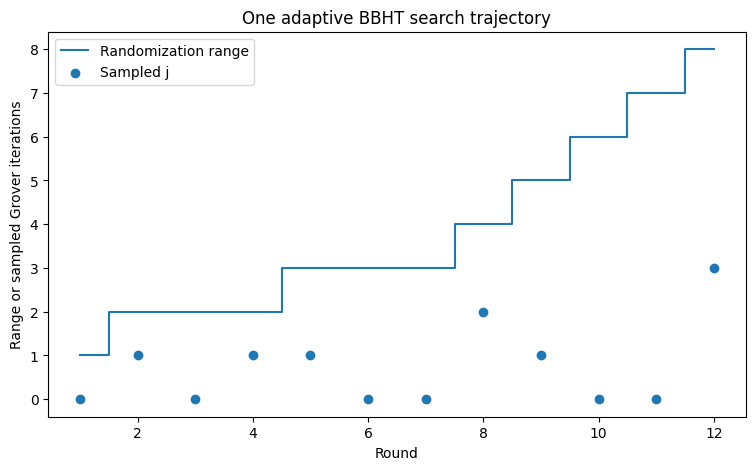

In [6]:
plt.figure(figsize=(9, 5))
plt.step(
    example_history_df["round"],
    example_history_df["m_integer"],
    where="mid",
    label="Randomization range",
)
plt.scatter(
    example_history_df["round"],
    example_history_df["j"],
    label="Sampled j",
)
plt.xlabel("Round")
plt.ylabel("Range or sampled Grover iterations")
plt.title("One adaptive BBHT search trajectory")
plt.legend()
plt.show()

## 6. Monte Carlo estimate of complete search cost

A complete adaptive run is random because both the sampled iteration count and the measurement outcome are random.

For each configuration, the experiment records the distribution of

$$
Q_G,
\qquad
Q_{\mathrm{phase}},
\qquad
Q_{\mathrm{table}},
\qquad
R.
$$

The primary end to end query metric in this notebook is

$$
Q_{\mathrm{phase}}
=
Q_G+R,
$$

because it includes the verification work omitted by $Q_G$.

The BBHT style table lookup metric is reported separately so that comparisons with the database lookup accounting in the original paper remain explicit.

### Monte Carlo uncertainty

A reported mean from finitely many simulated runs is itself an estimate.

For a cost variable $Q$ observed over $R_{\mathrm{MC}}$ independent runs, the estimated standard error of the sample mean is

$$
\operatorname{SE}(\bar Q)
=
\frac{s_Q}
{\sqrt{R_{\mathrm{MC}}}},
$$

where $s_Q$ is the sample standard deviation.

A normal approximation $95\%$ confidence interval is reported as

$$
\bar Q
\pm
1.96\,
\operatorname{SE}(\bar Q).
$$

These intervals quantify Monte Carlo sampling uncertainty in the estimated mean. They do not describe the much broader run to run distribution of adaptive search cost.

In [7]:
def mean_uncertainty(series, z=1.96):
    values = pd.Series(series, dtype=float)

    n = int(values.size)
    mean = float(values.mean())
    std = float(values.std(ddof=1))
    se = float(std / np.sqrt(n))

    return {
        "mean": mean,
        "std": std,
        "se": se,
        "ci_low": float(mean - z * se),
        "ci_high": float(mean + z * se),
    }


def simulate_adaptive_bbht(
    N,
    s,
    growth=6/5,
    runs=5000,
    base_seed=1000,
):
    records = []

    for r in range(runs):
        result = run_adaptive_bbht(
            N=N,
            s=s,
            growth=growth,
            seed=base_seed + r,
        )

        records.append({
            "grover_iterations":
                result["grover_iterations"],
            "phase_oracle_queries":
                result["phase_oracle_queries"],
            "table_lookup_queries":
                result["table_lookup_queries"],
            "rounds":
                result["rounds"],
        })

    df = pd.DataFrame(records)
    sqrt_scale = sqrt(N / s)

    grover_u = mean_uncertainty(
        df["grover_iterations"]
    )

    phase_u = mean_uncertainty(
        df["phase_oracle_queries"]
    )

    table_u = mean_uncertainty(
        df["table_lookup_queries"]
    )

    rounds_u = mean_uncertainty(
        df["rounds"]
    )

    summary = {
        "N": N,
        "s": s,
        "growth": growth,
        "runs": runs,
        "sqrt_N_over_s": sqrt_scale,

        "mean_grover_iterations":
            grover_u["mean"],
        "std_grover_iterations":
            grover_u["std"],
        "se_grover_iterations":
            grover_u["se"],
        "ci95_low_grover_iterations":
            grover_u["ci_low"],
        "ci95_high_grover_iterations":
            grover_u["ci_high"],

        "median_grover_iterations":
            float(df["grover_iterations"].median()),
        "q90_grover_iterations":
            float(df["grover_iterations"].quantile(0.90)),
        "q95_grover_iterations":
            float(df["grover_iterations"].quantile(0.95)),

        "mean_phase_oracle_queries":
            phase_u["mean"],
        "std_phase_oracle_queries":
            phase_u["std"],
        "se_phase_oracle_queries":
            phase_u["se"],
        "ci95_low_phase_oracle_queries":
            phase_u["ci_low"],
        "ci95_high_phase_oracle_queries":
            phase_u["ci_high"],

        "mean_table_lookup_queries":
            table_u["mean"],
        "std_table_lookup_queries":
            table_u["std"],
        "se_table_lookup_queries":
            table_u["se"],
        "ci95_low_table_lookup_queries":
            table_u["ci_low"],
        "ci95_high_table_lookup_queries":
            table_u["ci_high"],

        "mean_rounds":
            rounds_u["mean"],
        "se_rounds":
            rounds_u["se"],
        "ci95_low_rounds":
            rounds_u["ci_low"],
        "ci95_high_rounds":
            rounds_u["ci_high"],

        "ratio_grover_to_sqrt_scale":
            grover_u["mean"] / sqrt_scale,
        "ratio_phase_to_sqrt_scale":
            phase_u["mean"] / sqrt_scale,
        "ratio_table_to_sqrt_scale":
            table_u["mean"] / sqrt_scale,

        "se_ratio_grover_to_sqrt_scale":
            grover_u["se"] / sqrt_scale,
        "se_ratio_phase_to_sqrt_scale":
            phase_u["se"] / sqrt_scale,
        "se_ratio_table_to_sqrt_scale":
            table_u["se"] / sqrt_scale,
    }

    return summary, df

## 7. Fixed $N$ scaling sweep

Fix

$$
N=1024
$$

and vary $s$.

The theoretical statement

$$
\mathbb E[Q]
=
O\!\left(
\sqrt{\frac Ns}
\right)
$$

does **not** require the finite instance ratio

$$
\frac{\mathbb E[Q_G]}
{\sqrt{N/s}}
$$

to be exactly constant for every tested value of $s$.

Integer effects, the early adaptive rounds, the cap at

$$
\sqrt N,
$$

and departures from the sparse solution regime can all change the finite instance constant.

The fixed $N$ sweep therefore asks two separate questions.

First, does the mean Grover iteration cost decrease approximately linearly with

$$
\sqrt{\frac Ns}?
$$

Second, how does the normalized ratio itself change across the tested finite range?

A systematic change in the ratio is treated as a finite size observation to explain, not as an automatic failure of the square root scaling law.

In [8]:
N_fixed = 1024
s_values = [1, 2, 4, 8, 16, 32, 64]

fixed_N_rows = []

for s in s_values:
    summary, _ = simulate_adaptive_bbht(
        N=N_fixed,
        s=s,
        growth=6/5,
        runs=3000,
        base_seed=10_000 + s,
    )
    fixed_N_rows.append(summary)

fixed_N_df = pd.DataFrame(fixed_N_rows)
fixed_N_df

,N,s,growth,runs,sqrt_N_over_s,mean_grover_iterations,std_grover_iterations,se_grover_iterations,ci95_low_grover_iterations,ci95_high_grover_iterations,...,mean_rounds,se_rounds,ci95_low_rounds,ci95_high_rounds,ratio_grover_to_sqrt_scale,ratio_phase_to_sqrt_scale,ratio_table_to_sqrt_scale,se_ratio_grover_to_sqrt_scale,se_ratio_phase_to_sqrt_scale,se_ratio_table_to_sqrt_scale
0,1024,1,1.2,3000,32.000000,37.076000,22.249327,0.406215,36.279818,37.872182,...,14.555667,0.068739,14.420939,14.690394,1.158625,1.613490,2.772115,0.012694,0.014636,0.027315
1,1024,2,1.2,3000,22.627417,24.411000,16.335106,0.298237,23.826456,24.995544,...,12.511667,0.068997,12.376432,12.646902,1.078824,1.631767,2.710591,0.013180,0.015935,0.029086
2,1024,4,1.2,3000,16.000000,15.790667,11.329267,0.206843,15.385254,16.196079,...,10.608333,0.064995,10.480943,10.735724,0.986917,1.649938,2.636854,0.012928,0.016554,0.029425
3,1024,8,1.2,3000,11.313708,9.757333,7.142697,0.130407,9.501735,10.012931,...,8.682000,0.059484,8.565411,8.798589,0.862435,1.629822,2.492257,0.011526,0.016287,0.027723
4,1024,16,1.2,3000,8.000000,5.908667,4.975263,0.090835,5.730629,6.086704,...,6.927667,0.054803,6.820253,7.035081,0.738583,1.604542,2.343125,0.011354,0.017486,0.028678
5,1024,32,1.2,3000,5.656854,3.480667,3.309574,0.060424,3.362235,3.599098,...,5.292333,0.047508,5.199217,5.385450,0.615301,1.550862,2.166163,0.010682,0.018177,0.028609
6,1024,64,1.2,3000,4.000000,1.880667,1.684450,0.030754,1.820389,1.940944,...,3.850000,0.036339,3.778776,3.921224,0.470167,1.432667,1.902833,0.007688,0.015929,0.023306


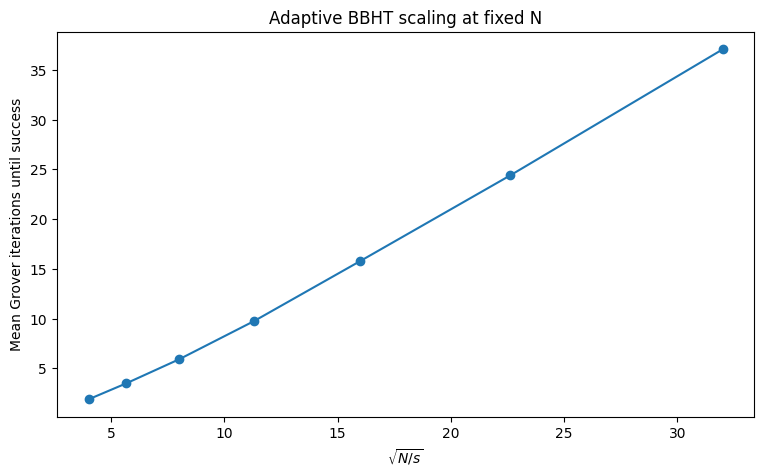

In [9]:
plt.figure(figsize=(9, 5))
plt.plot(
    fixed_N_df["sqrt_N_over_s"],
    fixed_N_df["mean_grover_iterations"],
    marker="o",
)
plt.xlabel(r"$\sqrt{N/s}$")
plt.ylabel("Mean Grover iterations until success")
plt.title("Adaptive BBHT scaling at fixed N")
plt.show()

### 7.1 Finite instance normalized cost

Inspect

$$
\rho_G
=
\frac{\mathbb E[Q_G]}
{\sqrt{N/s}},
$$

together with the complete phase oracle metric

$$
\rho_{\mathrm{phase}}
=
\frac{\mathbb E[Q_{\mathrm{phase}}]}
{\sqrt{N/s}}.
$$

The purpose is to describe how the finite instance constant changes across $s$.

No claim of exact constancy is made.

In [10]:
fixed_N_ratio_df = fixed_N_df[
    [
        "N",
        "s",
        "sqrt_N_over_s",
        "ratio_grover_to_sqrt_scale",
        "ratio_phase_to_sqrt_scale",
        "ratio_table_to_sqrt_scale",
    ]
].copy()

fixed_N_ratio_df

,N,s,sqrt_N_over_s,ratio_grover_to_sqrt_scale,ratio_phase_to_sqrt_scale,ratio_table_to_sqrt_scale
0,1024,1,32.000000,1.158625,1.613490,2.772115
1,1024,2,22.627417,1.078824,1.631767,2.710591
2,1024,4,16.000000,0.986917,1.649938,2.636854
3,1024,8,11.313708,0.862435,1.629822,2.492257
4,1024,16,8.000000,0.738583,1.604542,2.343125
5,1024,32,5.656854,0.615301,1.550862,2.166163
6,1024,64,4.000000,0.470167,1.432667,1.902833


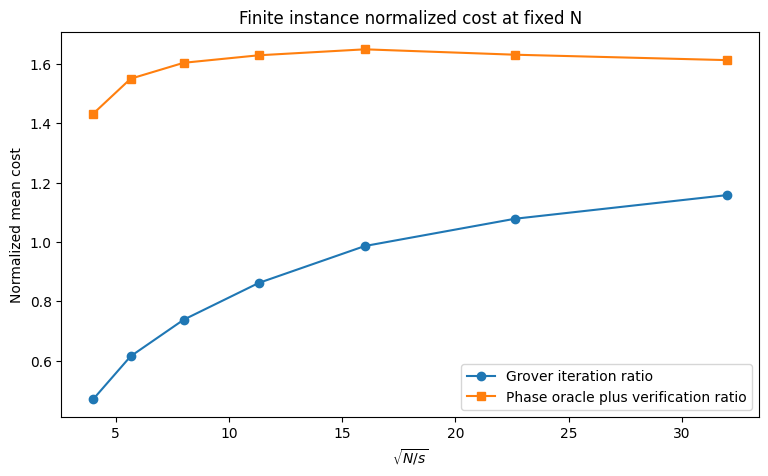

In [11]:
plt.figure(figsize=(9, 5))

plt.plot(
    fixed_N_ratio_df["sqrt_N_over_s"],
    fixed_N_ratio_df["ratio_grover_to_sqrt_scale"],
    marker="o",
    label="Grover iteration ratio",
)

plt.plot(
    fixed_N_ratio_df["sqrt_N_over_s"],
    fixed_N_ratio_df["ratio_phase_to_sqrt_scale"],
    marker="s",
    label="Phase oracle plus verification ratio",
)

plt.xlabel(r"$\sqrt{N/s}$")
plt.ylabel("Normalized mean cost")
plt.title("Finite instance normalized cost at fixed N")
plt.legend()
plt.show()

### 7.2 Uncertainty of the estimated means

The table below reports the estimated mean complete phase oracle cost together with its Monte Carlo standard error and $95\%$ confidence interval.

This separates uncertainty in the estimated mean from the much wider distribution of individual run costs.

In [12]:
fixed_N_uncertainty_df = fixed_N_df[
    [
        "N",
        "s",
        "sqrt_N_over_s",
        "mean_phase_oracle_queries",
        "se_phase_oracle_queries",
        "ci95_low_phase_oracle_queries",
        "ci95_high_phase_oracle_queries",
    ]
].copy()

fixed_N_uncertainty_df

,N,s,sqrt_N_over_s,mean_phase_oracle_queries,se_phase_oracle_queries,ci95_low_phase_oracle_queries,ci95_high_phase_oracle_queries
0,1024,1,32.000000,51.631667,0.468364,50.713673,52.549660
1,1024,2,22.627417,36.922667,0.360572,36.215945,37.629389
2,1024,4,16.000000,26.399000,0.264867,25.879861,26.918139
3,1024,8,11.313708,18.439333,0.184261,18.078182,18.800485
4,1024,16,8.000000,12.836333,0.139889,12.562152,13.110515
5,1024,32,5.656854,8.773000,0.102824,8.571466,8.974534
6,1024,64,4.000000,5.730667,0.063717,5.605782,5.855552


## 8. Scaling diagnostics for iteration cost and complete phase oracle cost

The BBHT theorem concerns expected Grover iteration cost, so

$$
Q_G
$$

remains the primary theorem aligned quantity.

However, the implementation also tracks the complete phase oracle cost

$$
Q_{\mathrm{phase}}
=
Q_G+R.
$$

These two quantities need not have identical finite instance behavior because the number of verification rounds contributes an additional scale dependent term.

A high quality fit to

$$
\mathbb E[Q_G]
\approx
c\sqrt{\frac Ns}
+
b
$$

is useful, but the fitted slope $c$ is only a finite range empirical parameter.

It must not be interpreted as a universal or asymptotic BBHT constant.

Three complementary diagnostics are applied to both $Q_G$ and $Q_{\mathrm{phase}}$.

### 8.1 Linear fit with an intercept

$$
\mathbb E[Q]
\approx
c\sqrt{\frac Ns}+b.
$$

### 8.2 Zero intercept fit

$$
\mathbb E[Q]
\approx
c_0\sqrt{\frac Ns}.
$$

### 8.3 Log log exponent fit

$$
\log \mathbb E[Q]
=
\alpha
+
\beta
\log\sqrt{\frac Ns}.
$$

If

$$
\beta\approx1,
$$

then the tested finite data are consistent with proportionality to the square root scale.

A value noticeably different from $1$ indicates finite range corrections or additional scale dependence in the selected cost metric.

None of these finite fits proves the asymptotic theorem.

In [13]:
x = fixed_N_df[
    "sqrt_N_over_s"
].to_numpy(dtype=float)

y_g = fixed_N_df[
    "mean_grover_iterations"
].to_numpy(dtype=float)

y_p = fixed_N_df[
    "mean_phase_oracle_queries"
].to_numpy(dtype=float)


def r_squared_score(observed, predicted):
    residual_sum = np.sum(
        (observed - predicted) ** 2
    )

    total_sum = np.sum(
        (observed - observed.mean()) ** 2
    )

    return float(
        1 - residual_sum / total_sum
    )


def scaling_diagnostics(x, y, label):
    slope, intercept = np.polyfit(
        x,
        y,
        1,
    )

    prediction_with_intercept = (
        slope * x + intercept
    )

    r2_with_intercept = r_squared_score(
        y,
        prediction_with_intercept,
    )

    zero_intercept_slope = float(
        np.dot(x, y)
        / np.dot(x, x)
    )

    prediction_zero_intercept = (
        zero_intercept_slope * x
    )

    r2_zero_intercept = r_squared_score(
        y,
        prediction_zero_intercept,
    )

    log_x = np.log(x)
    log_y = np.log(y)

    log_slope, log_intercept = np.polyfit(
        log_x,
        log_y,
        1,
    )

    log_prediction = (
        log_slope * log_x
        + log_intercept
    )

    r2_log = r_squared_score(
        log_y,
        log_prediction,
    )

    rows = [
        {
            "metric": label,
            "model": "linear with intercept",
            "slope_or_exponent": slope,
            "intercept": intercept,
            "R_squared": r2_with_intercept,
        },
        {
            "metric": label,
            "model": "zero intercept",
            "slope_or_exponent": zero_intercept_slope,
            "intercept": 0.0,
            "R_squared": r2_zero_intercept,
        },
        {
            "metric": label,
            "model": "log log exponent",
            "slope_or_exponent": log_slope,
            "intercept": log_intercept,
            "R_squared": r2_log,
        },
    ]

    return rows, {
        "slope": slope,
        "intercept": intercept,
        "zero_intercept_slope":
            zero_intercept_slope,
        "log_slope": log_slope,
        "log_intercept": log_intercept,
    }


grover_rows, grover_fit = (
    scaling_diagnostics(
        x,
        y_g,
        "Q_G",
    )
)

phase_rows, phase_fit = (
    scaling_diagnostics(
        x,
        y_p,
        "Q_phase",
    )
)

scaling_diagnostics_df = pd.DataFrame(
    grover_rows + phase_rows
)

scaling_diagnostics_df

,metric,model,slope_or_exponent,intercept,R_squared
0,Q_G,linear with intercept,1.264617,-3.949754,0.998255
1,Q_G,zero intercept,1.071021,0.000000,0.964709
2,Q_G,log log exponent,1.424419,-1.241275,0.996002
3,Q_phase,linear with intercept,1.637638,-0.338969,0.999491
4,Q_phase,zero intercept,1.621024,0.000000,0.999343
5,Q_phase,log log exponent,1.050102,0.339661,0.998400


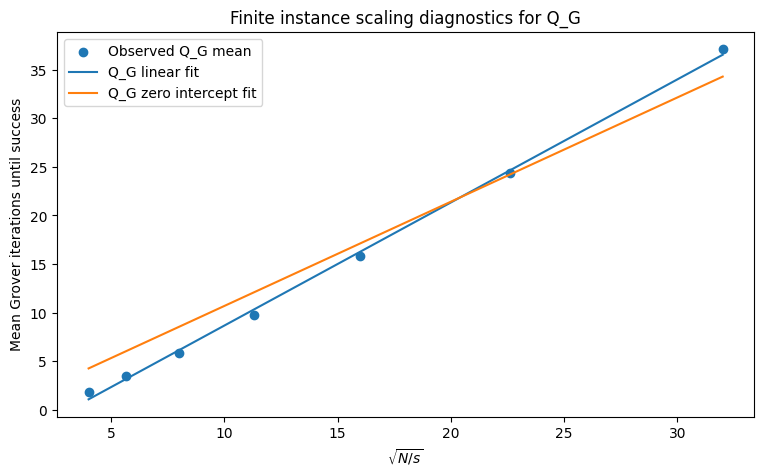

In [14]:
plt.figure(figsize=(9, 5))

plt.scatter(
    x,
    y_g,
    label="Observed Q_G mean",
)

x_line = np.linspace(
    x.min(),
    x.max(),
    200,
)

plt.plot(
    x_line,
    (
        grover_fit["slope"] * x_line
        + grover_fit["intercept"]
    ),
    label="Q_G linear fit",
)

plt.plot(
    x_line,
    (
        grover_fit["zero_intercept_slope"]
        * x_line
    ),
    label="Q_G zero intercept fit",
)

plt.xlabel(r"$\sqrt{N/s}$")
plt.ylabel("Mean Grover iterations until success")
plt.title("Finite instance scaling diagnostics for Q_G")
plt.legend()
plt.show()

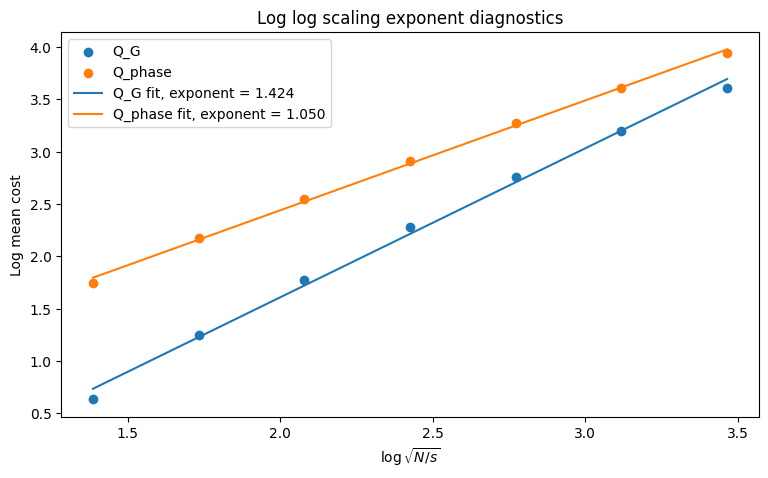

In [15]:
plt.figure(figsize=(9, 5))

log_x = np.log(x)

plt.scatter(
    log_x,
    np.log(y_g),
    label="Q_G",
)

plt.scatter(
    log_x,
    np.log(y_p),
    label="Q_phase",
)

log_x_line = np.linspace(
    log_x.min(),
    log_x.max(),
    200,
)

plt.plot(
    log_x_line,
    (
        grover_fit["log_slope"]
        * log_x_line
        + grover_fit["log_intercept"]
    ),
    label=(
        "Q_G fit, exponent = "
        f'{grover_fit["log_slope"]:.3f}'
    ),
)

plt.plot(
    log_x_line,
    (
        phase_fit["log_slope"]
        * log_x_line
        + phase_fit["log_intercept"]
    ),
    label=(
        "Q_phase fit, exponent = "
        f'{phase_fit["log_slope"]:.3f}'
    ),
)

plt.xlabel(r"$\log\sqrt{N/s}$")
plt.ylabel("Log mean cost")
plt.title("Log log scaling exponent diagnostics")
plt.legend()
plt.show()

## 9. Cross scale sweep and empirical scale collapse

A fit at one value of $N$ is not enough.

Now vary both $N$ and $s$ and examine whether the observed behavior is primarily controlled by

$$
x
=
\sqrt{\frac Ns}.
$$

Two complementary views are used.

First, inspect the normalized cost

$$
\frac{\mathbb E[Q_G]}
{\sqrt{N/s}}
$$

across all tested pairs.

Second, group different $(N,s)$ pairs that have the same value of

$$
\sqrt{\frac Ns}.
$$

If those independent pairs produce similar normalized costs, then the finite data exhibit an empirical scale collapse onto the variable

$$
\sqrt{\frac Ns}.
$$

Because equal values of

$$
\frac{s}{N}
$$

produce the same Grover angle

$$
\theta
=
\arcsin\sqrt{\frac{s}{N}},
$$

the ideal single round success probabilities are identical for equal marked fractions.

The adaptive growth rule is also identical until the cap

$$
m=\sqrt N
$$

becomes relevant.

Therefore, an observed collapse is best interpreted as a consistency check on the finite implementation and the effect of the cap, not as independent proof of the asymptotic scaling law.

It remains a useful finite empirical observation.

In [16]:
N_values = [
    64,
    128,
    256,
    512,
    1024,
    2048,
]

s_candidates = [
    1,
    2,
    4,
    8,
    16,
    32,
]

cross_rows = []

for N in N_values:
    for s in s_candidates:
        if s >= N:
            continue

        if s > 3 * N / 4:
            continue

        summary, _ = simulate_adaptive_bbht(
            N=N,
            s=s,
            growth=6/5,
            runs=1500,
            base_seed=N * 100 + s,
        )

        cross_rows.append(summary)

cross_scale_df = pd.DataFrame(
    cross_rows
)

cross_scale_df

,N,s,growth,runs,sqrt_N_over_s,mean_grover_iterations,std_grover_iterations,se_grover_iterations,ci95_low_grover_iterations,ci95_high_grover_iterations,...,mean_rounds,se_rounds,ci95_low_rounds,ci95_high_rounds,ratio_grover_to_sqrt_scale,ratio_phase_to_sqrt_scale,ratio_table_to_sqrt_scale,se_ratio_grover_to_sqrt_scale,se_ratio_phase_to_sqrt_scale,se_ratio_table_to_sqrt_scale
0,64,1,1.2,1500,8.000000,5.886000,4.397791,0.113550,5.663441,6.108559,...,6.922000,0.077025,6.771032,7.072968,0.735750,1.601000,2.336750,0.014194,0.023187,0.037222
1,64,2,1.2,1500,5.656854,3.416667,2.694667,0.069576,3.280298,3.553036,...,5.266000,0.063459,5.141620,5.390380,0.603987,1.534893,2.138880,0.012299,0.022708,0.034756
2,64,4,1.2,1500,4.000000,1.983333,1.772705,0.045771,1.893622,2.073045,...,3.908667,0.052606,3.805559,4.011774,0.495833,1.473000,1.968833,0.011443,0.023478,0.034516
3,64,8,1.2,1500,2.828427,1.119333,1.044583,0.026971,1.066470,1.172197,...,2.868667,0.040153,2.789967,2.947366,0.395744,1.409971,1.805715,0.009536,0.022385,0.031345
4,64,16,1.2,1500,2.000000,0.664000,0.675827,0.017450,0.629798,0.698202,...,2.199333,0.029156,2.142187,2.256479,0.332000,1.431667,1.763667,0.008725,0.021416,0.029275
5,64,32,1.2,1500,1.414214,0.577333,1.354465,0.034972,0.508788,0.645879,...,1.972000,0.036895,1.899685,2.044315,0.408236,1.802651,2.210887,0.024729,0.048604,0.072574
6,128,1,1.2,1500,11.313708,9.659333,6.711083,0.173279,9.319706,9.998961,...,8.694000,0.083205,8.530918,8.857082,0.853773,1.622221,2.475993,0.015316,0.022129,0.037342
7,128,2,1.2,1500,8.000000,5.778667,4.373072,0.112912,5.557359,5.999975,...,6.903333,0.075305,6.755735,7.050932,0.722333,1.585250,2.307583,0.014114,0.022871,0.036824
8,128,4,1.2,1500,5.656854,3.372667,2.695916,0.069608,3.236234,3.509099,...,5.262000,0.064112,5.136341,5.387659,0.596209,1.526408,2.122617,0.012305,0.022851,0.034910
9,128,8,1.2,1500,4.000000,1.868000,1.702697,0.043963,1.781832,1.954168,...,3.802667,0.049564,3.705522,3.899812,0.467000,1.417667,1.884667,0.010991,0.022147,0.032696


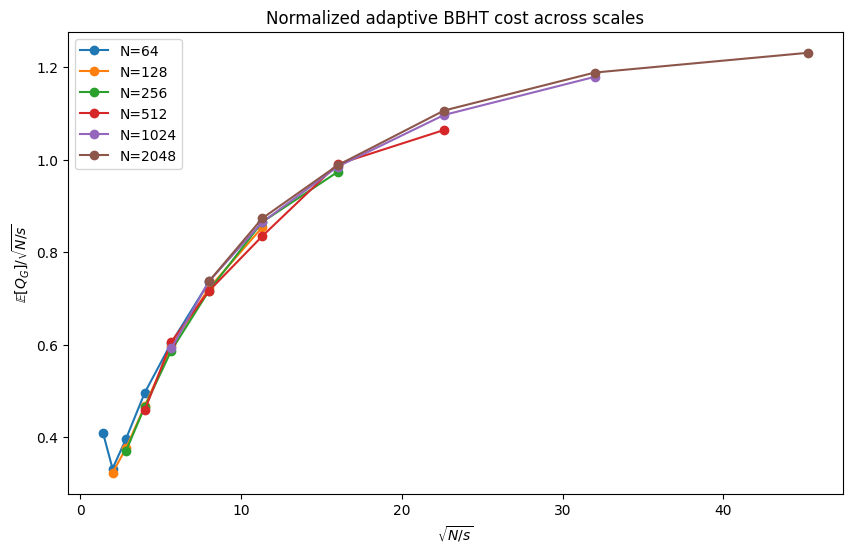

In [17]:
plt.figure(figsize=(10, 6))

for N in N_values:
    subset = cross_scale_df[
        cross_scale_df["N"] == N
    ]

    plt.plot(
        subset["sqrt_N_over_s"],
        subset["ratio_grover_to_sqrt_scale"],
        marker="o",
        label=f"N={N}",
    )

plt.xlabel(r"$\sqrt{N/s}$")
plt.ylabel(
    r"$\mathbb{E}[Q_G] / \sqrt{N/s}$"
)
plt.title("Normalized adaptive BBHT cost across scales")
plt.legend()
plt.show()

### 9.1 Group equal square root scales

For each repeated value of

$$
x
=
\sqrt{\frac Ns},
$$

compute the mean normalized cost across the corresponding $(N,s)$ pairs, together with the spread across those pairs.

A small spread indicates that different problem sizes collapse onto approximately the same finite behavior when expressed through $x$.

In [18]:
collapse_input_df = cross_scale_df.copy()

collapse_input_df[
    "sqrt_scale_key"
] = collapse_input_df[
    "sqrt_N_over_s"
].round(12)

collapse_summary_df = (
    collapse_input_df
    .groupby("sqrt_scale_key")
    .agg(
        pair_count=(
            "ratio_grover_to_sqrt_scale",
            "size",
        ),
        mean_normalized_grover_cost=(
            "ratio_grover_to_sqrt_scale",
            "mean",
        ),
        std_normalized_grover_cost=(
            "ratio_grover_to_sqrt_scale",
            "std",
        ),
        min_normalized_grover_cost=(
            "ratio_grover_to_sqrt_scale",
            "min",
        ),
        max_normalized_grover_cost=(
            "ratio_grover_to_sqrt_scale",
            "max",
        ),
        mean_normalized_phase_cost=(
            "ratio_phase_to_sqrt_scale",
            "mean",
        ),
    )
    .reset_index()
    .sort_values("sqrt_scale_key")
)

collapse_summary_df[
    "range_normalized_grover_cost"
] = (
    collapse_summary_df[
        "max_normalized_grover_cost"
    ]
    - collapse_summary_df[
        "min_normalized_grover_cost"
    ]
)

collapse_summary_df

,sqrt_scale_key,pair_count,mean_normalized_grover_cost,std_normalized_grover_cost,min_normalized_grover_cost,max_normalized_grover_cost,mean_normalized_phase_cost,range_normalized_grover_cost
0,1.414214,1,0.408236,NaN,0.408236,0.408236,1.802651,0.000000
1,2.000000,2,0.327500,0.006364,0.323000,0.332000,1.423500,0.009000
2,2.828427,3,0.380423,0.013591,0.369817,0.395744,1.383572,0.025927
3,4.000000,4,0.471542,0.016660,0.458000,0.495833,1.430375,0.037833
4,5.656854,5,0.597152,0.007946,0.587370,0.606226,1.524569,0.018856
5,8.000000,6,0.727583,0.010183,0.716333,0.737167,1.587111,0.020833
6,11.313708,5,0.858333,0.014922,0.834681,0.873218,1.624154,0.038537
7,16.000000,4,0.984125,0.007407,0.973500,0.990208,1.646187,0.016708
8,22.627417,3,1.089111,0.022059,1.064255,1.106357,1.646125,0.042102
9,32.000000,2,1.183802,0.006585,1.179146,1.188458,1.641875,0.009313


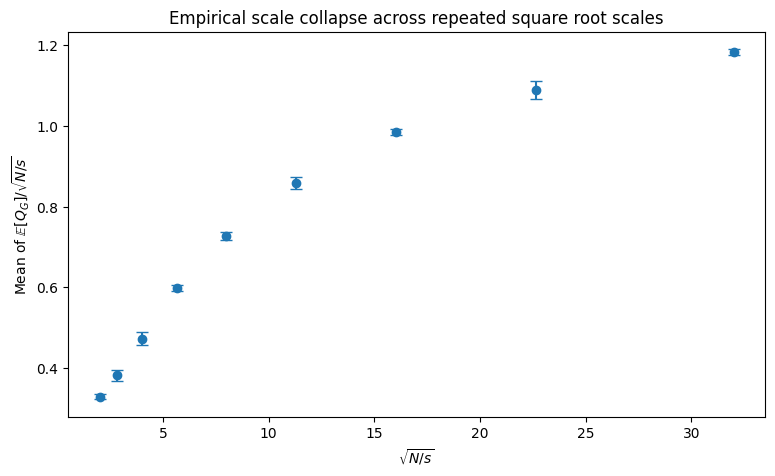

In [19]:
repeated_scale_df = collapse_summary_df[
    collapse_summary_df["pair_count"] > 1
].copy()

plt.figure(figsize=(9, 5))

plt.errorbar(
    repeated_scale_df["sqrt_scale_key"],
    repeated_scale_df["mean_normalized_grover_cost"],
    yerr=repeated_scale_df[
        "std_normalized_grover_cost"
    ].fillna(0.0),
    fmt="o",
    capsize=4,
)

plt.xlabel(r"$\sqrt{N/s}$")
plt.ylabel(
    r"Mean of $\mathbb{E}[Q_G] / \sqrt{N/s}$"
)
plt.title("Empirical scale collapse across repeated square root scales")
plt.show()

## 10. Cost distribution and reliability

The expected cost is important for complexity, but it does not describe how variable individual adaptive searches are.

A randomized adaptive procedure can have a right skewed cost distribution in which most searches finish relatively quickly while a smaller number of runs continue for much longer.

For selected cases, compare:

$$
\text{mean},
\qquad
\text{median},
\qquad
\text{standard deviation},
\qquad
q_{0.90},
\qquad
q_{0.95}.
$$

Two additional descriptive quantities are useful.

The coefficient of variation is

$$
\operatorname{CV}
=
\frac{\operatorname{std}(Q_G)}
{\mathbb E[Q_G]}.
$$

The upper tail to median ratio is

$$
T_{90}
=
\frac{q_{0.90}}
{\operatorname{median}(Q_G)}.
$$

If the mean is substantially above the median and the upper quantiles are much larger than the median, then mean cost alone hides meaningful run to run variability.

This section describes the reliability profile of the adaptive search. It is separate from the Monte Carlo standard error of the mean.

In [20]:
distribution_cases = [
    (256, 1),
    (256, 4),
    (1024, 1),
    (1024, 16),
]

distribution_rows = []
distribution_samples = {}

for N, s in distribution_cases:
    summary, samples = simulate_adaptive_bbht(
        N=N,
        s=s,
        growth=6/5,
        runs=5000,
        base_seed=N + 10 * s,
    )

    summary = dict(summary)

    median_q = summary[
        "median_grover_iterations"
    ]

    mean_q = summary[
        "mean_grover_iterations"
    ]

    std_q = summary[
        "std_grover_iterations"
    ]

    q90 = summary[
        "q90_grover_iterations"
    ]

    summary[
        "coefficient_of_variation"
    ] = (
        std_q / mean_q
        if mean_q > 0
        else np.nan
    )

    summary[
        "q90_to_median_ratio"
    ] = (
        q90 / median_q
        if median_q > 0
        else np.nan
    )

    distribution_rows.append(summary)
    distribution_samples[(N, s)] = samples

distribution_df = pd.DataFrame(
    distribution_rows
)

distribution_df[
    [
        "N",
        "s",
        "mean_grover_iterations",
        "median_grover_iterations",
        "std_grover_iterations",
        "q90_grover_iterations",
        "q95_grover_iterations",
        "coefficient_of_variation",
        "q90_to_median_ratio",
    ]
]

,N,s,mean_grover_iterations,median_grover_iterations,std_grover_iterations,q90_grover_iterations,q95_grover_iterations,coefficient_of_variation,q90_to_median_ratio
0,256,1,15.2198,14.0,10.202564,29.0,34.0,0.670348,2.071429
1,256,4,5.7774,5.0,4.511931,12.0,14.0,0.780962,2.400000
2,1024,1,36.5648,34.0,22.177154,67.0,77.0,0.606516,1.970588
3,1024,16,5.8000,5.0,4.750212,12.0,14.0,0.819002,2.400000


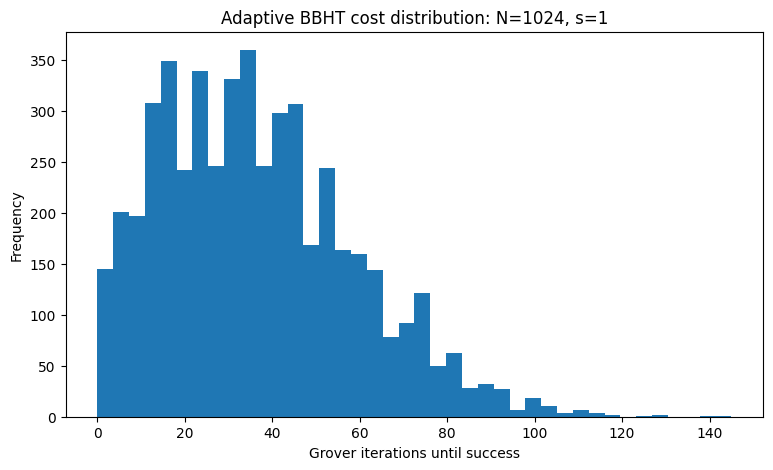

In [21]:
hist_df = distribution_samples[(1024, 1)]

plt.figure(figsize=(9, 5))
plt.hist(
    hist_df["grover_iterations"],
    bins=40,
)
plt.xlabel("Grover iterations until success")
plt.ylabel("Frequency")
plt.title("Adaptive BBHT cost distribution: N=1024, s=1")
plt.show()

### 10.1 Empirical cumulative distribution

The empirical cumulative distribution shows what fraction of runs finish below a given Grover iteration cost.

This makes upper tail behavior easier to interpret than a mean alone.

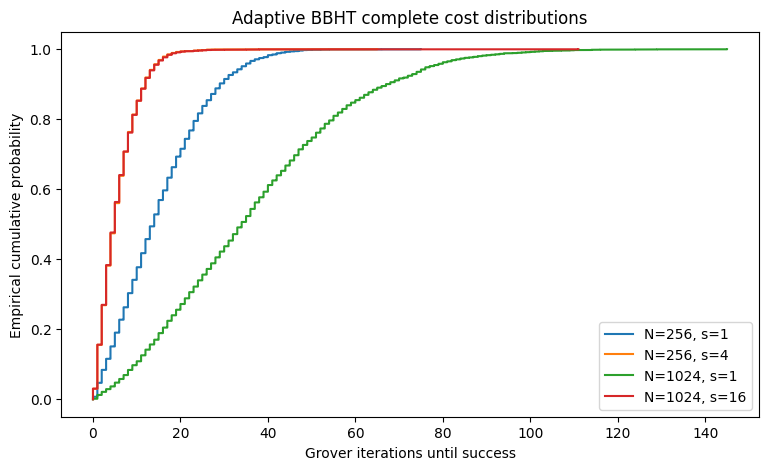

In [22]:
plt.figure(figsize=(9, 5))

for N, s in distribution_cases:
    values = np.sort(
        distribution_samples[
            (N, s)
        ]["grover_iterations"].to_numpy()
    )

    cumulative = (
        np.arange(1, len(values) + 1)
        / len(values)
    )

    plt.step(
        values,
        cumulative,
        where="post",
        label=f"N={N}, s={s}",
    )

plt.xlabel("Grover iterations until success")
plt.ylabel("Empirical cumulative probability")
plt.title("Adaptive BBHT complete cost distributions")
plt.legend()
plt.show()

## 11. Sensitivity to the growth factor $\lambda$

BBHT allows

$$
1<\lambda<\frac43.
$$

Test

$$
1.10,\quad
1.15,\quad
1.20,\quad
1.25,\quad
1.30.
$$

A smaller value explores the range more gradually. A larger value reaches larger ranges faster.

The key question is **not** which value has the smallest aggregate average over all cases.

Instead, compare the growth factors separately for every tested $(N,s)$ pair.

The primary comparison uses the complete phase oracle metric

$$
Q_{\mathrm{phase}}.
$$

For each case, report:

1. the point estimate of the mean,
2. its Monte Carlo standard error,
3. its $95\%$ confidence interval,
4. the growth factor with the lowest point estimate,
5. and whether competing confidence intervals overlap the interval of that point estimate winner.

Confidence interval overlap is used only as a descriptive uncertainty check, not as a formal hypothesis test.

A growth factor should be described as consistently better only if the case by case evidence supports that conclusion.

In [23]:
growth_values = [
    1.10,
    1.15,
    1.20,
    1.25,
    1.30,
]

growth_cases = [
    (256, 1),
    (256, 4),
    (1024, 1),
    (1024, 16),
]

growth_rows = []

for growth in growth_values:
    for N, s in growth_cases:
        summary, _ = simulate_adaptive_bbht(
            N=N,
            s=s,
            growth=growth,
            runs=2500,
            base_seed=int(
                100_000 * growth
            ) + N + s,
        )

        growth_rows.append(summary)

growth_df = pd.DataFrame(
    growth_rows
)

growth_df[
    [
        "N",
        "s",
        "growth",
        "mean_phase_oracle_queries",
        "se_phase_oracle_queries",
        "ci95_low_phase_oracle_queries",
        "ci95_high_phase_oracle_queries",
        "mean_rounds",
    ]
]

,N,s,growth,mean_phase_oracle_queries,se_phase_oracle_queries,ci95_low_phase_oracle_queries,ci95_high_phase_oracle_queries,mean_rounds
0,256,1,1.10,33.3504,0.366512,32.632037,34.068763,15.7560
1,256,4,1.10,15.0672,0.192395,14.690106,15.444294,9.0760
2,1024,1,1.10,67.7268,0.702098,66.350687,69.102913,23.2064
3,1024,16,1.10,14.9880,0.191603,14.612459,15.363541,9.0488
4,256,1,1.15,28.5816,0.311852,27.970370,29.192830,12.2428
5,256,4,1.15,13.0988,0.151892,12.801092,13.396508,7.4396
6,1024,1,1.15,57.0096,0.590121,55.852964,58.166236,17.3876
7,1024,16,1.15,13.2684,0.152481,12.969538,13.567262,7.5272
8,256,1,1.20,26.0412,0.272140,25.507806,26.574594,10.5392
9,256,4,1.20,12.8044,0.144828,12.520538,13.088262,6.9104


In [24]:
growth_summary_df = (
    growth_df
    .groupby("growth")
    .agg(
        mean_normalized_phase_cost=(
            "ratio_phase_to_sqrt_scale",
            "mean",
        ),
        mean_normalized_grover_cost=(
            "ratio_grover_to_sqrt_scale",
            "mean",
        ),
        mean_rounds=(
            "mean_rounds",
            "mean",
        ),
    )
    .reset_index()
)

growth_summary_df

,growth,mean_normalized_phase_cost,mean_normalized_grover_cost,mean_rounds
0,1.10,1.989441,0.995553,14.2718
1,1.15,1.715950,0.921103,11.1493
2,1.20,1.614091,0.901191,9.7533
3,1.25,1.514984,0.871750,8.7097
4,1.30,1.462187,0.867119,7.9510


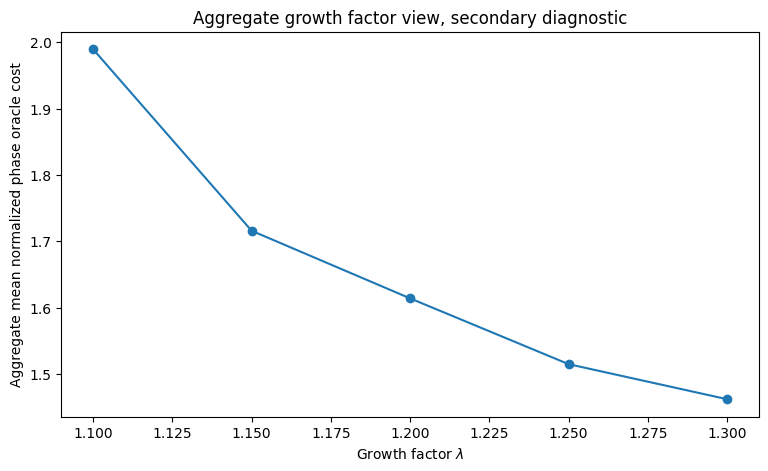

In [25]:
plt.figure(figsize=(9, 5))

plt.plot(
    growth_summary_df["growth"],
    growth_summary_df[
        "mean_normalized_phase_cost"
    ],
    marker="o",
)

plt.xlabel(r"Growth factor $\lambda$")
plt.ylabel(
    "Aggregate mean normalized phase oracle cost"
)
plt.title(
    "Aggregate growth factor view, secondary diagnostic"
)
plt.show()

### 11.1 Case by case comparison

The table below identifies the smallest point estimate for each problem instance and checks which other growth factors have $95\%$ confidence intervals overlapping the winner's interval.

This prevents an aggregate average from hiding instance dependent behavior.

In [26]:
growth_case_rows = []

for (N, s), subset in growth_df.groupby(
    ["N", "s"]
):
    subset = subset.sort_values(
        "growth"
    ).copy()

    winner_idx = subset[
        "mean_phase_oracle_queries"
    ].idxmin()

    winner = subset.loc[
        winner_idx
    ]

    winner_low = winner[
        "ci95_low_phase_oracle_queries"
    ]

    winner_high = winner[
        "ci95_high_phase_oracle_queries"
    ]

    overlapping_growths = []

    for _, row in subset.iterrows():
        overlaps = not (
            row[
                "ci95_high_phase_oracle_queries"
            ] < winner_low
            or row[
                "ci95_low_phase_oracle_queries"
            ] > winner_high
        )

        if overlaps:
            overlapping_growths.append(
                float(row["growth"])
            )

    growth_case_rows.append({
        "N": int(N),
        "s": int(s),
        "point_estimate_best_lambda":
            float(winner["growth"]),
        "best_mean_phase_queries":
            float(
                winner[
                    "mean_phase_oracle_queries"
                ]
            ),
        "best_ci95_low":
            float(winner_low),
        "best_ci95_high":
            float(winner_high),
        "lambdas_with_overlapping_95pct_CI":
            overlapping_growths,
    })

growth_case_summary_df = pd.DataFrame(
    growth_case_rows
)

growth_case_summary_df

,N,s,point_estimate_best_lambda,best_mean_phase_queries,best_ci95_low,best_ci95_high,lambdas_with_overlapping_95pct_CI
0,256,1,1.30,22.9140,22.475195,23.352805,[1.3]
1,256,4,1.25,11.9848,11.709690,12.259910,"[1.25, 1.3]"
2,1024,1,1.30,45.2008,44.318961,46.082639,[1.3]
3,1024,16,1.30,12.0292,11.731420,12.326980,"[1.25, 1.3]"


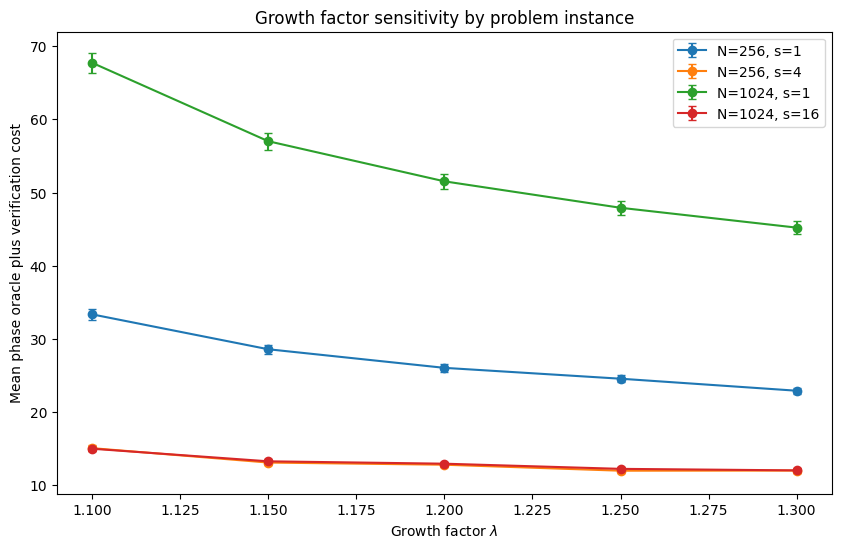

In [27]:
plt.figure(figsize=(10, 6))

for (N, s), subset in growth_df.groupby(
    ["N", "s"]
):
    subset = subset.sort_values(
        "growth"
    )

    plt.errorbar(
        subset["growth"],
        subset["mean_phase_oracle_queries"],
        yerr=1.96
        * subset["se_phase_oracle_queries"],
        marker="o",
        capsize=3,
        label=f"N={N}, s={s}",
    )

plt.xlabel(r"Growth factor $\lambda$")
plt.ylabel(
    "Mean phase oracle plus verification cost"
)
plt.title(
    "Growth factor sensitivity by problem instance"
)
plt.legend()
plt.show()

## 12. Fair comparison with known $s$

A direct comparison between adaptive **expected cost until success** and the iteration count of one deterministic first peak run is not fair.

Those quantities answer different questions.

If $s$ is known and a fixed deterministic value $t$ is used repeatedly until success, then one attempt succeeds with probability

$$
P(t)
=
\sin^2((2t+1)\theta).
$$

Under the phase oracle plus verification model, one attempt costs

$$
t+1,
$$

so the expected complete cost until success is

$$
C_{\mathrm{phase}}(t)
=
\frac{t+1}{P(t)}.
$$

Under the BBHT style table lookup model, one attempt costs

$$
2t+1,
$$

giving

$$
C_{\mathrm{table}}(t)
=
\frac{2t+1}{P(t)}.
$$

This notebook searches the integer values of $t$ over one Grover probability period and records the best restart benchmark for each complete cost model.

The pure Grover iteration quantity

$$
\frac{t}{P(t)}
$$

is deliberately **not** used as the fairness benchmark. At $t=0$ it assigns zero cost to repeated classical candidate sampling because verification is outside that metric.

The earlier first peak iteration count is retained only as a reference for near maximum single attempt success. It is not called an overhead benchmark.

### Exact finite search for the restart optimum

The restart benchmark is searched over increasing integer values of $t$ with a rigorous stopping condition.

Because

$$
P(t)\le1,
$$

we have

$$
C_{\mathrm{phase}}(t)
=
\frac{t+1}{P(t)}
\ge
t+1
$$

and

$$
C_{\mathrm{table}}(t)
=
\frac{2t+1}{P(t)}
\ge
2t+1.
$$

Once these lower bounds for all later values exceed the best costs already found, no later integer $t$ can improve the benchmark.

This avoids assuming that the integer sampled Grover probabilities repeat exactly after one continuous oscillation period.


In [28]:
def best_first_peak_integer(N, s):
    theta = theta_from_N_s(N, s)

    t_cont = (
        np.pi / (4 * theta)
        - 0.5
    )

    candidates = sorted(set([
        max(0, int(np.floor(t_cont))),
        max(0, int(np.ceil(t_cont))),
    ]))

    return max(
        candidates,
        key=lambda t:
            grover_probability(N, s, t),
    )


def known_s_restart_benchmark(N, s):
    best_phase_cost = float("inf")
    best_phase_t = None

    best_table_cost = float("inf")
    best_table_t = None

    t = 0

    while True:
        p = grover_probability(
            N,
            s,
            t,
        )

        phase_cost = (
            (t + 1) / p
        )

        table_cost = (
            (2 * t + 1) / p
        )

        if phase_cost < best_phase_cost:
            best_phase_cost = phase_cost
            best_phase_t = t

        if table_cost < best_table_cost:
            best_table_cost = table_cost
            best_table_t = t

        # Since P(t) <= 1,
        #
        # C_phase(t) >= t + 1
        # C_table(t) >= 2t + 1.
        #
        # Once both lower bounds exceed the
        # best costs already found, no later t
        # can improve either benchmark.
        next_t = t + 1

        phase_lower_bound_next = (
            next_t + 1
        )

        table_lower_bound_next = (
            2 * next_t + 1
        )

        if (
            phase_lower_bound_next
            > best_phase_cost
            and
            table_lower_bound_next
            > best_table_cost
        ):
            break

        t = next_t

    return {
        "known_s_first_peak_iterations":
            best_first_peak_integer(N, s),

        "known_s_phase_optimal_t":
            int(best_phase_t),
        "known_s_phase_expected_cost":
            float(best_phase_cost),

        "known_s_table_optimal_t":
            int(best_table_t),
        "known_s_table_expected_cost":
            float(best_table_cost),
    }


benchmark_rows = []

for _, row in fixed_N_df.iterrows():
    N = int(row["N"])
    s = int(row["s"])

    known = known_s_restart_benchmark(
        N,
        s,
    )

    benchmark_rows.append({
        "N": N,
        "s": s,

        **known,

        "adaptive_mean_grover_iterations":
            row["mean_grover_iterations"],

        "adaptive_mean_phase_queries":
            row["mean_phase_oracle_queries"],

        "adaptive_mean_table_queries":
            row["mean_table_lookup_queries"],

        "phase_uncertainty_factor":
            (
                row["mean_phase_oracle_queries"]
                / known[
                    "known_s_phase_expected_cost"
                ]
            ),

        "table_uncertainty_factor":
            (
                row["mean_table_lookup_queries"]
                / known[
                    "known_s_table_expected_cost"
                ]
            ),
    })

known_s_comparison_df = pd.DataFrame(
    benchmark_rows
)

known_s_comparison_df

,N,s,known_s_first_peak_iterations,known_s_phase_optimal_t,known_s_phase_expected_cost,known_s_table_optimal_t,known_s_table_expected_cost,adaptive_mean_grover_iterations,adaptive_mean_phase_queries,adaptive_mean_table_queries,phase_uncertainty_factor,table_uncertainty_factor
0,1024,1,25,18,22.675431,18,44.157418,37.076000,51.631667,88.707667,2.276987,2.008896
1,1024,2,17,13,16.196855,13,31.236791,24.411000,36.922667,61.333667,2.279620,1.963507
2,1024,4,12,9,11.618773,9,22.075670,15.790667,26.399000,42.189667,2.272099,1.911139
3,1024,8,8,6,8.397838,6,15.595984,9.757333,18.439333,28.196667,2.195724,1.807944
4,1024,16,6,4,6.124621,4,11.024318,5.908667,12.836333,18.745000,2.095858,1.700332
5,1024,32,4,3,4.459624,3,7.804343,3.480667,8.773000,12.253667,1.967206,1.570109
6,1024,64,3,2,3.302338,2,5.503897,1.880667,5.730667,7.611333,1.735336,1.382899


## 12.1 Comparison with the BBHT proof bound

The BBHT analysis gives an expected upper bound proportional to the critical range scale.

Using

$$
m_0
=
\frac{1}{\sin(2\theta)},
$$

the proof bound used for comparison here is

$$
\frac92 m_0.
$$

This is a theorem level upper bound, not an expected equality.

Comparing the finite Monte Carlo mean with this quantity shows how conservative the proof bound is on the tested instances.

In [29]:
bbht_bound_rows = []

for _, row in fixed_N_df.iterrows():
    N = int(row["N"])
    s = int(row["s"])

    theta = theta_from_N_s(
        N,
        s,
    )

    m0_continuous = (
        1 / sin(2 * theta)
    )

    proof_upper_bound = (
        4.5 * m0_continuous
    )

    bbht_bound_rows.append({
        "N": N,
        "s": s,
        "m0_continuous":
            m0_continuous,
        "BBHT_upper_bound_9m0_over_2":
            proof_upper_bound,
        "observed_mean_Q_G":
            row["mean_grover_iterations"],
        "observed_over_bound":
            (
                row["mean_grover_iterations"]
                / proof_upper_bound
            ),
    })

bbht_bound_df = pd.DataFrame(
    bbht_bound_rows
)

bbht_bound_df

,N,s,m0_continuous,BBHT_upper_bound_9m0_over_2,observed_mean_Q_G,observed_over_bound
0,1024,1,16.007818,72.035182,37.076000,0.514693
1,1024,2,11.324773,50.961480,24.411000,0.479009
2,1024,4,8.015671,36.070519,15.790667,0.437772
3,1024,8,5.679082,25.555867,9.757333,0.381804
4,1024,16,4.031621,18.142295,5.908667,0.325685
5,1024,32,2.873685,12.931582,3.480667,0.269160
6,1024,64,2.065591,9.295160,1.880667,0.202328


## 13. Analysis questions

### 13.1 Is the adaptive Grover iteration cost empirically consistent with square root scaling?

Yes, with important finite instance corrections.

For the theorem aligned Grover iteration metric

$$
Q_G,
$$

the fixed $N=1024$ fit with an intercept is

$$
\mathbb E[Q_G]
\approx
1.2646
\sqrt{\frac Ns}
-
3.9498,
$$

with

$$
R^2
\approx
0.9983.
$$

The zero intercept fit is

$$
\mathbb E[Q_G]
\approx
1.0710
\sqrt{\frac Ns},
$$

with

$$
R^2
\approx
0.9647.
$$

The log log exponent is

$$
\beta_G
\approx
1.4244,
$$

so the tested finite range does not behave as a pure proportional law in $Q_G$.

The complete phase oracle metric behaves more cleanly:

$$
\mathbb E[Q_{\mathrm{phase}}]
\approx
1.6376
\sqrt{\frac Ns}
-
0.3390,
$$

with

$$
R^2
\approx
0.9995,
$$

while the zero intercept fit gives

$$
\mathbb E[Q_{\mathrm{phase}}]
\approx
1.6210
\sqrt{\frac Ns},
$$

with

$$
R^2
\approx
0.9993.
$$

Its log log exponent is

$$
\beta_{\mathrm{phase}}
\approx
1.0501.
$$

The observed behavior is therefore consistent with the expected square root scale, but the finite instance corrections are much stronger in $Q_G$ than in the complete phase oracle metric.

### 13.2 Do different $(N,s)$ pairs collapse onto the same square root scale?

Yes, within the tested finite model.

Pairs with the same value of

$$
\sqrt{\frac Ns}
$$

show closely matching normalized Grover iteration costs.

For example, at

$$
\sqrt{\frac Ns}
=
8,
$$

six different $(N,s)$ pairs produce normalized values between approximately

$$
0.7163
$$

and

$$
0.7372,
$$

with mean

$$
0.7276
$$

and standard deviation approximately

$$
0.0102.
$$

This agreement is expected structurally because equal values of $s/N$ give the same Grover angle

$$
\theta
=
\arcsin
\sqrt{\frac{s}{N}},
$$

and therefore the same ideal success probabilities for every sampled $j$.

The adaptive growth rule is also identical until the cap

$$
m
=
\sqrt N
$$

becomes relevant.

The observed collapse is therefore best interpreted as a consistency check on the implementation and finite cap behavior, rather than as independent proof of the asymptotic theorem.

### 13.3 How broad is the complete search cost distribution?

The distributions have substantial right tails.

For

$$
N=1024,
\qquad
s=1,
$$

the Grover iteration cost has

$$
\text{mean}
=
36.56,
\qquad
\text{median}
=
34,
$$

while

$$
q_{0.90}
=
67
$$

and

$$
q_{0.95}
=
77.
$$

The coefficient of variation is approximately

$$
0.607.
$$

For the easier tested case

$$
N=1024,
\qquad
s=16,
$$

the mean is approximately

$$
5.80,
$$

the median is

$$
5,
$$

and

$$
q_{0.90}
=
12,
\qquad
q_{0.95}
=
14.
$$

Its coefficient of variation is approximately

$$
0.819.
$$

Thus the expected cost is a valid complexity statistic, but it does not characterize the variability of individual adaptive searches. A nontrivial fraction of runs require substantially more Grover iterations than the mean.

### 13.4 What finite instance cost is associated with not knowing $s$?

The adaptive search pays a finite constant factor relative to a fair known $s$ restart benchmark.

For

$$
N=1024,
\qquad
s=1,
$$

the optimal known $s$ restart cost under the complete phase oracle model is approximately

$$
22.675,
$$

while the adaptive unknown $s$ mean is approximately

$$
51.632.
$$

The resulting finite uncertainty factor is

$$
2.277.
$$

As the number of marked states increases, this factor decreases.

At

$$
s=64,
$$

the known $s$ complete phase oracle benchmark is approximately

$$
3.302,
$$

while the adaptive mean is approximately

$$
5.731,
$$

giving an uncertainty factor of approximately

$$
1.735.
$$

The corresponding table lookup uncertainty factors decrease from approximately

$$
2.009
$$

at $s=1$ to approximately

$$
1.383
$$

at $s=64$.

The adaptive method therefore preserves efficient scaling while paying a finite search cost for not knowing the useful Grover scale in advance.

### 13.5 How sensitive is performance to $\lambda$?

Performance depends meaningfully on the growth factor, but no tested value dominates every instance.

For the sparse cases

$$
(N,s)
=
(256,1)
$$

and

$$
(1024,1),
$$

the smallest complete phase oracle means occur at

$$
\lambda
=
1.30,
$$

and the corresponding $95\%$ confidence intervals do not overlap those of the next smaller tested values.

For

$$
(256,4)
$$

and

$$
(1024,16),
$$

the smallest point estimates occur at $\lambda=1.25$ and $\lambda=1.30$ respectively, but the $95\%$ confidence intervals for $\lambda=1.25$ and $\lambda=1.30$ overlap.

The aggregate normalized phase oracle cost decreases across the tested values from approximately

$$
1.989
$$

at $\lambda=1.10$ to approximately

$$
1.462
$$

at $\lambda=1.30$.

This aggregate trend is informative, but the case specific confidence intervals show that it should not be interpreted as evidence for a universally optimal growth factor.

### 13.6 Does verification overhead materially change the scaling picture?

Yes.

The three reported resources are

$$
Q_G,
\qquad
Q_{\mathrm{phase}}
=
Q_G+R,
\qquad
Q_{\mathrm{table}}
=
2Q_G+R.
$$

At

$$
N=1024,
\qquad
s=1,
$$

the normalized means are approximately

$$
\frac{\mathbb E[Q_G]}
{\sqrt{N/s}}
=
1.159,
$$

$$
\frac{\mathbb E[Q_{\mathrm{phase}}]}
{\sqrt{N/s}}
=
1.613,
$$

and

$$
\frac{\mathbb E[Q_{\mathrm{table}}]}
{\sqrt{N/s}}
=
2.772.
$$

At

$$
s=64,
$$

the corresponding values are approximately

$$
0.470,
\qquad
1.433,
\qquad
1.903.
$$

Verification therefore changes the finite instance constants substantially, especially for easier instances where the number of rounds is large relative to the number of Grover iterations.

This is also why $Q_G$ and $Q_{\mathrm{phase}}$ exhibit different finite range scaling diagnostics.

### 13.7 Where does the sparse solution approximation stop being informative?

The approximation

$$
m_0
\approx
\frac12
\sqrt{\frac Ns}
$$

is accurate only when

$$
s\ll N.
$$

The exact critical scale is

$$
m_0
=
\frac{1}{\sin(2\theta)}
=
\frac{N}
{2\sqrt{s(N-s)}}.
$$

For

$$
\frac{s}{N}
=
\frac1{16},
$$

the exact value is approximately

$$
2.066,
$$

while the sparse approximation gives

$$
2.
$$

The difference is small.

For

$$
\frac{s}{N}
=
\frac14,
$$

the exact value is approximately

$$
1.155,
$$

while the approximation gives

$$
1.
$$

For

$$
\frac{s}{N}
=
\frac12,
$$

the exact value is

$$
1,
$$

while the approximation gives approximately

$$
0.707.
$$

Thus the approximation becomes progressively less informative as the marked fraction grows, even though the exact BBHT analysis remains valid within the stated regime.

### 13.8 Are the Monte Carlo means estimated precisely enough?

Yes for the purposes of the comparisons made here.

For

$$
N=1024,
\qquad
s=1,
$$

the estimated complete phase oracle mean is

$$
51.632
$$

with standard error approximately

$$
0.468
$$

and $95\%$ confidence interval

$$
[50.714,\ 52.550].
$$

For

$$
s=64,
$$

the mean is approximately

$$
5.731,
$$

with standard error approximately

$$
0.064
$$

and interval

$$
[5.606,\ 5.856].
$$

These intervals are narrow relative to the much broader run to run cost distributions.

The Monte Carlo mean is therefore estimated with useful precision, while the individual adaptive search cost remains intrinsically variable.

### 13.9 What question remains after adaptive BBHT?

The central unknown $s$ question has now been addressed empirically.

Adaptive range growth reaches useful Grover scales without estimating $s$ directly, and the observed finite results are consistent with the proven BBHT square root query behavior.

The next research question is therefore comparative:

$$
\boxed{
\text{How does adaptive BBHT compare with other strategies for handling uncertainty in }s
\text{ on finite instances?}
}
$$

Useful comparison dimensions include query constants, variability, robustness, prior information requirements, and implementation cost.

## 14. Results and interpretation

### 14.1 A complete adaptive trajectory reaches success without knowing $s$

For the representative case

$$
N=256,
\qquad
s=4,
\qquad
\lambda=\frac65,
$$

the executed run succeeds after

$$
12
$$

rounds.

The sampled Grover iteration counts accumulate to

$$
Q_G
=
9.
$$

Including one verification oracle evaluation per round gives

$$
Q_{\mathrm{phase}}
=
21,
$$

while BBHT style table lookup accounting gives

$$
Q_{\mathrm{table}}
=
30.
$$

The trajectory contains many early values of $j=0$ and $j=1$ because the randomization range begins small and grows gradually.

The successful round occurs after the range has reached approximately

$$
m
=
7.43,
$$

where the sampled value is

$$
j=3
$$

with ideal success probability approximately

$$
0.5914.
$$

This single trajectory illustrates the mechanism of adaptive search: inexpensive early attempts are followed by progressively broader randomization until a useful scale is reached.

### 14.2 Mean search cost follows the expected square root scale, with finite corrections

At fixed

$$
N=1024,
$$

the observed mean Grover iteration cost decreases from approximately

$$
37.08
$$

for $s=1$ to approximately

$$
1.88
$$

for $s=64$.

The corresponding complete phase oracle means decrease from approximately

$$
51.63
$$

to

$$
5.73.
$$

The linear fit for $Q_G$ is extremely strong over the tested range:

$$
\mathbb E[Q_G]
\approx
1.2646
\sqrt{\frac Ns}
-
3.9498,
$$

with

$$
R^2
\approx
0.9983.
$$

However, the log log exponent

$$
\beta_G
\approx
1.4244
$$

shows that the finite $Q_G$ data are not yet a pure proportional law.

The complete phase oracle metric behaves more nearly proportional to the theoretical scale:

$$
\mathbb E[Q_{\mathrm{phase}}]
\approx
1.6210
\sqrt{\frac Ns}
$$

under a zero intercept fit, with

$$
R^2
\approx
0.9993,
$$

and log log exponent

$$
\beta_{\mathrm{phase}}
\approx
1.0501.
$$

The correct interpretation is therefore not that a universal finite constant has been measured.

Instead, the tested adaptive search is strongly consistent with square root scale behavior, while finite integer effects, adaptive rounds, and verification overhead alter the observed constants.

### 14.3 Normalized cost is not constant, but equal marked fractions are highly consistent

At fixed $N$, the normalized Grover iteration ratio

$$
\frac{\mathbb E[Q_G]}
{\sqrt{N/s}}
$$

decreases as $s$ grows.

For $N=1024$, it changes from approximately

$$
1.159
$$

at $s=1$ to

$$
0.470
$$

at $s=64$.

This confirms that exact finite ratio constancy is not an appropriate criterion.

Across different problem sizes, however, pairs with the same marked fraction show highly consistent behavior.

At

$$
\sqrt{\frac Ns}
=
8,
$$

six different pairs have normalized Grover iteration costs between approximately

$$
0.7163
$$

and

$$
0.7372.
$$

Because equal marked fractions imply equal Grover angles and identical ideal success probabilities, this collapse is structurally expected.

It therefore serves as a strong implementation consistency check rather than independent evidence for the asymptotic theorem.

### 14.4 The adaptive cost distribution has a substantial right tail

The Monte Carlo distributions show that individual searches can differ considerably even when the expected cost is stable.

For

$$
N=1024,
\qquad
s=1,
$$

the mean Grover iteration cost is approximately

$$
36.56,
$$

while the median is

$$
34.
$$

The upper quantiles are

$$
q_{0.90}
=
67
$$

and

$$
q_{0.95}
=
77.
$$

For

$$
N=1024,
\qquad
s=16,
$$

the mean is approximately

$$
5.80,
$$

the median is

$$
5,
$$

and the upper quantiles are

$$
12
$$

and

$$
14.
$$

The empirical cumulative distributions confirm a noticeable right tail.

Therefore the mean captures expected query complexity, but median and upper quantiles are also necessary to describe the reliability of individual adaptive searches.

### 14.5 Growth factor choice changes finite instance performance

Across the tested values

$$
\lambda
\in
\{1.10,1.15,1.20,1.25,1.30\},
$$

larger values generally reduce the aggregate complete phase oracle cost.

The aggregate normalized mean decreases from approximately

$$
1.989
$$

at $\lambda=1.10$ to approximately

$$
1.462
$$

at $\lambda=1.30$.

The case specific analysis is more informative.

For both sparse $s=1$ cases, $\lambda=1.30$ has the smallest point estimate and its $95\%$ confidence interval does not overlap the intervals of the smaller tested values.

For the easier tested cases, $\lambda=1.25$ and $\lambda=1.30$ have overlapping intervals.

Thus the experiments show meaningful sensitivity to $\lambda$, but do not support a universal finite instance optimum.

### 14.6 Unknown $s$ introduces a finite but controlled cost

The fair known $s$ benchmark optimizes expected complete restart cost rather than comparing against one first peak run.

At

$$
N=1024,
\qquad
s=1,
$$

the known $s$ optimal complete phase oracle cost is approximately

$$
22.675,
$$

while adaptive BBHT requires approximately

$$
51.632
$$

on average.

The finite uncertainty factor is therefore approximately

$$
2.277.
$$

At

$$
s=64,
$$

the corresponding factor decreases to approximately

$$
1.735.
$$

The table lookup uncertainty factor similarly decreases from approximately

$$
2.009
$$

to

$$
1.383.
$$

The price of not knowing $s$ is therefore visible as a finite constant factor, not as a loss of the square root search scale.

### 14.7 Query accounting materially affects finite conclusions

The three cost models behave differently because they count different resources.

At $N=1024$ and $s=1$,

$$
\mathbb E[Q_G]
\approx
37.08,
$$

$$
\mathbb E[Q_{\mathrm{phase}}]
\approx
51.63,
$$

and

$$
\mathbb E[Q_{\mathrm{table}}]
\approx
88.71.
$$

The distinction becomes especially important for easier instances, where many rounds may contain very few Grover iterations.

Consequently, the theorem aligned iteration count and the complete implementation cost should both be reported rather than collapsed into a single ambiguous query metric.

### 14.8 Monte Carlo uncertainty is small relative to run variability

The key mean estimates are statistically precise.

For

$$
N=1024,
\qquad
s=1,
$$

the complete phase oracle mean has $95\%$ confidence interval

$$
[50.714,\ 52.550].
$$

For

$$
s=64,
$$

the corresponding interval is

$$
[5.606,\ 5.856].
$$

These intervals are narrow relative to the spread of individual run costs.

This distinction is important:

$$
\text{uncertainty in the estimated mean}
\neq
\text{variability of individual searches}.
$$

The simulation therefore estimates the expected cost precisely even though the adaptive search itself remains stochastic.

### 14.9 The BBHT proof bound is conservative on the tested instances

Using

$$
m_0
=
\frac1{\sin(2\theta)},
$$

the comparison bound is

$$
\frac92m_0.
$$

For

$$
N=1024,
\qquad
s=1,
$$

this gives approximately

$$
72.04,
$$

while the observed mean is

$$
37.08.
$$

The ratio of observed mean to proof bound is approximately

$$
0.515.
$$

Across the fixed $N$ sweep, this ratio decreases from approximately

$$
0.515
$$

at $s=1$ to approximately

$$
0.202
$$

at $s=64$.

The experimental means are therefore comfortably below the theoretical upper bound throughout the tested range.

This does not sharpen the theorem. It shows that the proof bound is conservative for these finite instances.

### 14.10 Overall interpretation

The adaptive randomized procedure succeeds without prior knowledge of $s$ and exhibits finite behavior consistent with the central BBHT result

$$
\mathbb E[Q_G]
=
O\!\left(
\sqrt{\frac Ns}
\right).
$$

The experiments also show what the asymptotic statement alone does not reveal.

Finite constants depend on the chosen cost model, the growth factor, the marked fraction, and verification overhead.

Individual search costs have substantial right tails.

The known $s$ advantage remains visible as a finite constant factor.

The BBHT proof bound is conservative relative to the observed means.

These effects are not contradictions of the theoretical result. They are the finite instance structure hidden inside the asymptotic scaling statement.

## 15. Conclusion and next research question

This notebook investigated whether adaptive randomized Grover search can reach a useful amplification scale when the number of marked states is unknown.

The answer from the tested finite instances is yes.

Starting from

$$
m=1
$$

and increasing the randomized range geometrically allows the search to discover useful Grover iteration scales without explicitly estimating $s$.

The observed Grover iteration costs are consistent with the proven BBHT square root behavior

$$
O\!\left(
\sqrt{\frac Ns}
\right),
$$

while the complete phase oracle metric shows especially clean finite proportional behavior over the tested range.

The experiments also reveal several finite instance effects that are not captured by asymptotic notation alone.

Verification contributes materially to total cost.

The adaptive cost distribution has a substantial right tail.

The growth factor $\lambda$ changes finite performance, with no tested value dominating every instance.

Not knowing $s$ introduces a finite constant factor relative to a fair known $s$ restart benchmark.

The empirical means remain comfortably below the BBHT proof bound across the tested fixed $N$ sweep.

The main result of this notebook is therefore not a new complexity theorem.

It is an empirical reproduction and finite implementation study of the BBHT unknown $s$ search mechanism, showing how the proven square root scaling appears together with query accounting, variability, growth factor sensitivity, verification overhead, and finite size effects.

The next research question is

$$
\boxed{
\text{How does adaptive BBHT compare with other strategies for handling uncertainty in }s
\text{ on finite instances?}
}
$$

That comparison can focus on expected query cost, tail behavior, robustness, prior information requirements, and implementation complexity.

## References

1. Michel Boyer, Gilles Brassard, Peter Høyer, and Alain Tapp, *Tight bounds on quantum searching*.
2. Lov K. Grover, *A fast quantum mechanical algorithm for database search*.
3. Gilles Brassard, Peter Høyer, Michele Mosca, and Alain Tapp, *Quantum Amplitude Amplification and Estimation*.